In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import glob
import json

sns.set_context("talk")
pd.options.display.max_columns = None

In [8]:
csv_files = glob.glob("../results/movebank/metrics/*.csv")
full_df = pd.concat((pd.read_csv(f) for f in csv_files), ignore_index=True)

species_metadata = pd.read_csv("../data/movebank/metadata/species_metadata.csv")
full_df = pd.merge(full_df, species_metadata, on=["species"])
full_df["movement"] = pd.Categorical(full_df["movement"], ['WALK', 'FLY', 'SWIM'])

full_df["final_sizes_raw"] = full_df["final_sizes"]
full_df["final_sizes"] = full_df["final_sizes_raw"].map(eval)
def count_scales(r):
    if r["final_sizes"] is not None:
        return len(r["final_sizes"]) + 1
    if r["num_stops"] > 0:
        return 1
    return 0
full_df["num_scales"] = full_df.apply(count_scales, axis=1)

df_10 = full_df[full_df["downsample_rate_minutes"] == 10]
df_60 = full_df[full_df["downsample_rate_minutes"] == 60]
df = df_60.copy()


2900/7790 animals


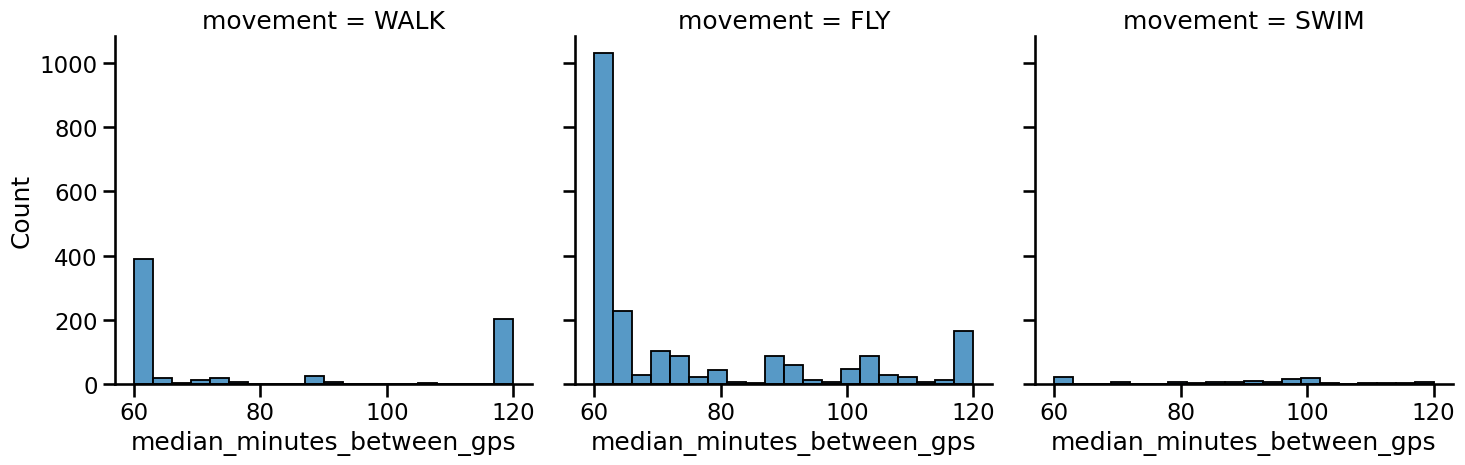

In [10]:
_df = df[
    (df["median_minutes_between_gps"] <= 120) &
    (df["days_spanned"] >= 60) &
    # (df["num_scales"] >= 2)
    True
]
print(f"{len(_df)}/{len(df)} animals")
p = sns.displot(data=_df, x="median_minutes_between_gps", col="movement", stat="count", common_norm=False, bins=20)


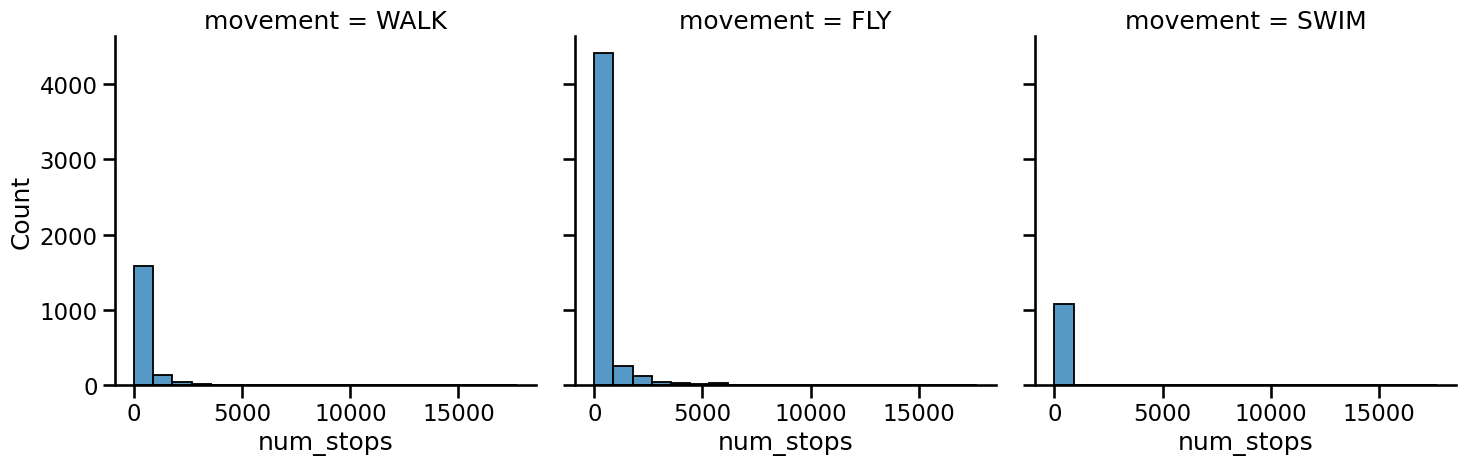

In [6]:
# p = sns.displot(data=df_10, x="num_stops", col="movement", stat="count", common_norm=False, bins=20)
p = sns.displot(data=df, x="num_stops", col="movement", stat="count", common_norm=False, bins=20)

2751/7790 animals


,num_scales
movement,
WALK,4.188144
FLY,3.798862
SWIM,2.850000


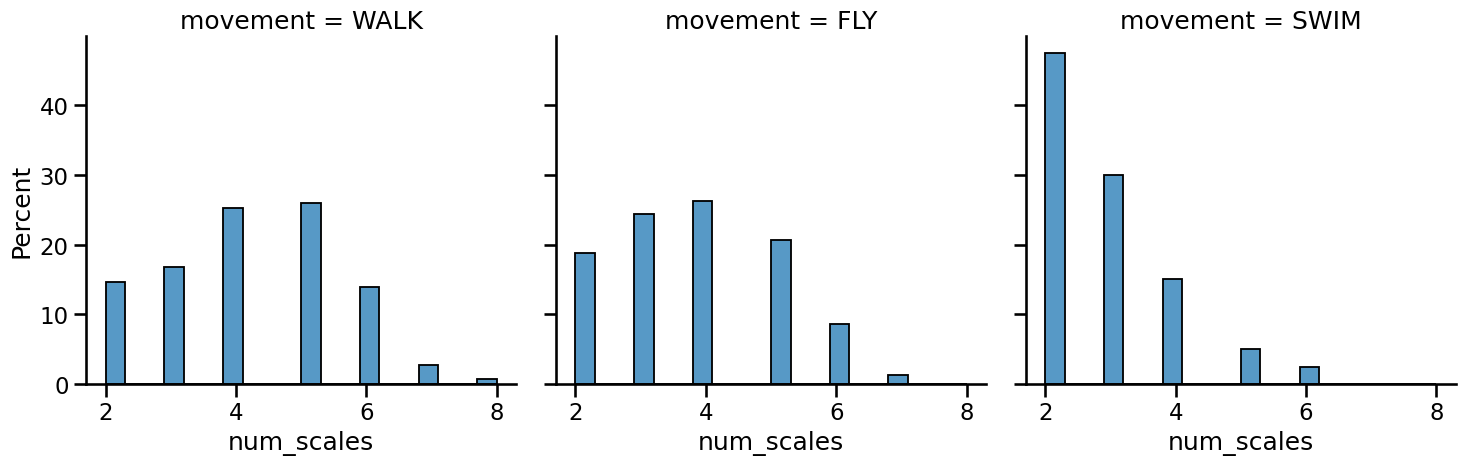

In [13]:
_df = df [
    # (df["median_minutes_between_gps"] <= 90) &
    (df["days_spanned"] >= 60) &
    (df["num_scales"] >= 2) &
    # (df["num_stops"] >= 10) &
    True
]
print(f"{len(_df)}/{len(df)} animals")
p = sns.displot(data=_df, x="num_scales", col="movement", stat="percent", common_norm=False, bins=20)
_df[["movement", "num_scales"]].groupby("movement", observed=True).mean("num_scales")